In [78]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage,SystemMessage
from pydantic import BaseModel,Field
import operator

In [79]:
generator_llm=ChatGoogleGenerativeAI(model='gemini-3.5-flash-lite')
evaluator_llm=ChatGoogleGenerativeAI(model='gemini-3.5-flash-lite')
optimizer_llm=ChatGoogleGenerativeAI(model='gemini-3.5-flash-lite')

In [80]:
class TweetState(TypedDict):
    topic:str
    tweet:str
    evaluation:Literal['approved','needs improvement']
    feed_back:str
    iteration:int
    max_iteration:int

    


In [81]:
class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the tweet.")

In [82]:
structured_evaluator_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [83]:
def generator(state:TweetState):
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
        Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

        Rules:
        - Do NOT use question-answer format.
        - Max 280 characters.
        - Use observational humor, irony, sarcasm, or cultural references.
        - Think in meme logic, punchlines, or relatable takes.
        - Use simple, day to day english
        """)
            ]

    # send generator_llm
    response = generator_llm.invoke(messages).content

    # return response
    return {'tweet': response, 'tweet_history': [response]}

In [84]:
def evaluator(state:TweetState):
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
        Evaluate the following tweet:

        Tweet: "{state['tweet']}"

        Use the criteria below to evaluate the tweet:

        1. Originality – Is this fresh, or have you seen it a hundred times before?  
        2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
        3. Punchiness – Is it short, sharp, and scroll-stopping?  
        4. Virality Potential – Would people retweet or share it?  
        5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

        Auto-reject if:
        - It's written in question-answer format (e.g., "Why did..." or "What happens when...")
        - It exceeds 280 characters
        - It reads like a traditional setup-punchline joke
        - Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

        ### Respond ONLY in structured format:
        - evaluation: "approved" or "needs_improvement"  
        - feedback: One paragraph explaining the strengths and weaknesses 
        """)
        ]

    response = structured_evaluator_llm.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}

In [85]:
def optimizer(state: TweetState):

    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
        Improve the tweet based on this feedback:
        "{state['feedback']}"

        Topic: "{state['topic']}"
        Original Tweet:
        {state['tweet']}

        Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
        """)
            ]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'tweet': response, 'iteration': iteration, 'tweet_history': [response]}

In [86]:
def check_condition(state:TweetState):
    if(state['evaluation']=="approved" or state['iteration']==state['max_iteration']):
        return "approved"
    else:
        return "needs improvement"

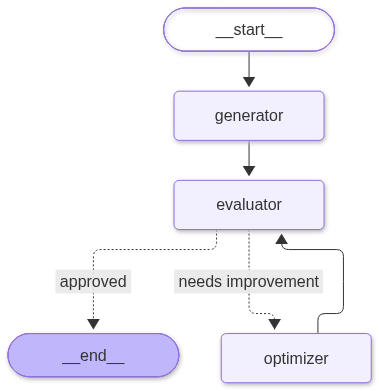

In [87]:
graph=StateGraph(TweetState)

graph.add_node("generator",generator)
graph.add_node("evaluator",evaluator)
graph.add_node("optimizer",optimizer)

graph.add_edge(START,"generator")
graph.add_edge("generator","evaluator")
graph.add_conditional_edges("evaluator",check_condition,{'approved':END,'needs improvement':'optimizer'})
graph.add_edge("optimizer","evaluator")

workflow=graph.compile()
workflow



In [88]:
initial_state = {
    "topic": "srhberhb",
    "iteration": 1,
    "max_iteration": 5
}
result = workflow.invoke(initial_state)

In [89]:
result

{'topic': 'srhberhb',
 'tweet': [{'type': 'text', 'text': 'Me trying to type my secure 6'},
  {'type': 'text',
   'text': '4-character password on the first try after one (1) espresso: srhberhb',
   'extras': {'signature': 'EpYBCpMBAWkUfRMEX9IRxaMOTwlkU3EJqYUwuJOeYRT0F/SdfCUc+IGVu6zHoZ7SrbRBxACr9leoaRj/bhqe4xLLbDJ2dG6A2plI9ryYur65MsaLPEczePvCrJ24Vz5lOPYCN+whycXVGOMSPZ78ZQTt3kPh2uOr5CuyVgOrtwdJpevV/QqFupW6VjvWj+f1HEJ4K9reARRv'}}],
 'evaluation': 'approved',
 'iteration': 1,
 'max_iteration': 5}